# Trabalho Integrado de Fundamentos de IA — Etapa 5
## Redes Bayesianas: Modelagem Causal, Inferência por Enumeração e d-Separação

**Equipe 2:** Domínio da Saúde Pública — Vigilância Epidemiológica e Vacinação PNI  
**Base de Dados:** Microdados Oficiais do PNI (2023–2026) — API de Dados Abertos do Ministério da Saúde  

---

### 1. Objetivos da Etapa 5
Nesta etapa, consolidamos o raciocínio sob incerteza em um modelo probabilístico estruturado:
1. **Desenho do DAG Causal:** Modelamos 5 variáveis críticas de saúde pública com justificativa explícita de cada aresta direcionada.
2. **Estimação das CPTs:** Aprendemos as Tabelas de Probabilidade Condicional a partir dos microdados do PNI.
3. **Inferência por Enumeração do Zero:** Implementamos o algoritmo exato clássico de enumeração sobre variáveis ocultas ($P(X \mid e) = \alpha \sum_Y P(X, e, Y)$).
4. **Validação com `pgmpy`:** Comparação formal com o algoritmo `VariableElimination`.
5. **Análise de d-Separação:** Demonstração teórica e empírica das três estruturas canônicas (cadeia, bifurcação e colisor / *v-structure*).
6. **Economia de Parâmetros:** Cálculo formal da redução de parâmetros em relação à distribuição conjunta completa ($2^n - 1$).

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from networkx.algorithms.d_separation import is_d_separator

sys.path.append(os.path.abspath('..'))
from src.utils import load_and_preprocess_pni
from src.bayesian_net import BayesianNetworkScratch

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination

np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

/home/luizg/trabalho_fia_final/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/luizg/trabalho_fia_final/.venv/lib/python3.13/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


### 2. Definição do Grafo Acíclico Dirigido (DAG) e Justificativas Causais

Definimos 5 variáveis binárias do domínio de Saúde Pública:
- $R$ (**Região Geográfica**): $1$ se Norte/Nordeste, $0$ se Sul/Sudeste/Centro-Oeste;
- $S$ (**Conexão da Unidade**): $1$ se Sistema Offline (sincronização periódica), $0$ se Online;
- $V$ (**Grupo de Vulnerabilidade Etária**): $1$ se Criança $\le 4$ anos ou Idoso $\ge 60$ anos, $0$ se Adulto/Jovem;
- $N$ (**Fabricante Nacional**): $1$ se Butantan/Fiocruz, $0$ se Multinacional (Pfizer, etc.);
- $A$ (**Atraso Crítico na Notificação**): $1$ se $>7$ dias de latência até a RNDS, $0$ se oportuno.

#### Justificativa Causal das Arestas:
1. $R \to S$: Municípios do Norte e Nordeste apresentam maiores proporções de postos rurais e isolados, aumentando a necessidade de operar via e-SUS offline.
2. $S \to A$: A operação offline exige exportação periódica de arquivos em pen-drive ou sincronização manual por lotes, sendo causa direta de atraso de notificação.
3. $V \to N$: Os calendários vacinais infantis e de idosos no Brasil utilizam prioritariamente vacinas produzidas pelos institutos públicos nacionais (Butantan e Fiocruz).
4. $N \to A$: O fabricante dita a complexidade da cadeia logística, loteamento e processos de conferência no estoque do posto antes da digitação.

> **Estrutura de Colisor:** Note que $A$ é um nó **colisor** no caminho $S \to A \leftarrow N$.

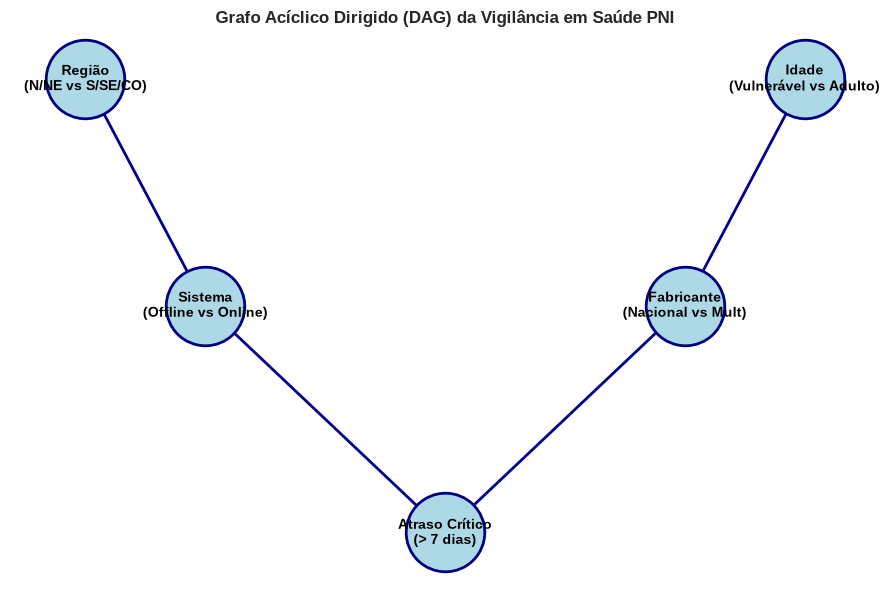

In [2]:
# Construção do DAG e Plot com NetworkX
edges = [
    ('R', 'S'),
    ('S', 'A'),
    ('V', 'N'),
    ('N', 'A')
]

G = nx.DiGraph(edges)
pos = {
    'R': (-1.5, 1.0),
    'S': (-1.0, 0.0),
    'V': (1.5, 1.0),
    'N': (1.0, 0.0),
    'A': (0.0, -1.0)
}

labels = {
    'R': 'Região\n(N/NE vs S/SE/CO)',
    'S': 'Sistema\n(Offline vs Online)',
    'V': 'Idade\n(Vulnerável vs Adulto)',
    'N': 'Fabricante\n(Nacional vs Mult)',
    'A': 'Atraso Crítico\n(> 7 dias)'
}

plt.figure(figsize=(9, 6))
nx.draw_networkx_nodes(G, pos, node_size=3200, node_color='lightblue', edgecolors='navy', linewidths=2)
nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=25, edge_color='darkblue', width=2)
nx.draw_networkx_labels(G, pos, labels=labels, font_size=10, font_weight='bold')
plt.title('Grafo Acíclico Dirigido (DAG) da Vigilância em Saúde PNI', fontsize=12, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

### 3. Preparação dos Microdados e Estimação das CPTs
Mapeamos os atributos para a forma binária discreta e estimamos as 5 CPTs da rede.

In [3]:
df = load_and_preprocess_pni('../data/vacinacao_pni_amostra.parquet')

df_bn = pd.DataFrame()
df_bn['R'] = df['regiao'].apply(lambda r: 1 if r in ['Norte', 'Nordeste'] else 0)
df_bn['S'] = df['sistema_offline'].astype(int)
df_bn['V'] = df['faixa_etaria'].apply(lambda f: 1 if f in ['Crianca', 'Idoso'] else 0)
df_bn['N'] = df['fabricante'].apply(lambda f: 1 if f in ['Butantan', 'Fiocruz'] else 0)
df_bn['A'] = df['atraso_critico'].astype(int)

bn_scratch = BayesianNetworkScratch()
bn_scratch.fit(df_bn)

print("=== CPTs APRENDIDAS (DO ZERO) ===")
print(f"P(R=1) [Norte/Nordeste]                       : {bn_scratch.cpt_R[1]:.4f}")
print(f"P(S=1 | R=0) [Offline dado Outras Regiões]    : {bn_scratch.cpt_S_R[0][1]:.4f}")
print(f"P(S=1 | R=1) [Offline dado Norte/Nordeste]    : {bn_scratch.cpt_S_R[1][1]:.4f}")
print(f"P(V=1) [Idade Vulnerável: Criança/Idoso]       : {bn_scratch.cpt_V[1]:.4f}")
print(f"P(N=1 | V=0) [Nacional dado Adulto]           : {bn_scratch.cpt_N_V[0][1]:.4f}")
print(f"P(N=1 | V=1) [Nacional dado Vulnerável]       : {bn_scratch.cpt_N_V[1][1]:.4f}")

print("\nCPT de Atraso P(A=1 | S, N) [Nó Colisor]:")
for s in [0, 1]:
    for n in [0, 1]:
        s_label = 'Offline' if s == 1 else 'Online '
        n_label = 'Nacional' if n == 1 else 'Multinacional'
        prob_a = bn_scratch.cpt_A_SN[(s, n)][1]
        print(f"  P(A=1 | S={s_label}, N={n_label}) = {prob_a:.4f} ({prob_a*100:.2f}%)")

[Data Loader] 16000 registros brutos carregados.
[Data Loader] 15403 registros válidos após higienização.
[Distribuição Alvo] Atraso Crítico (>7 dias): 51.6% positivo.
=== CPTs APRENDIDAS (DO ZERO) ===
P(R=1) [Norte/Nordeste]                       : 0.2907
P(S=1 | R=0) [Offline dado Outras Regiões]    : 0.5077
P(S=1 | R=1) [Offline dado Norte/Nordeste]    : 0.5242
P(V=1) [Idade Vulnerável: Criança/Idoso]       : 0.4357
P(N=1 | V=0) [Nacional dado Adulto]           : 0.4770
P(N=1 | V=1) [Nacional dado Vulnerável]       : 0.3925

CPT de Atraso P(A=1 | S, N) [Nó Colisor]:
  P(A=1 | S=Online , N=Multinacional) = 0.3059 (30.59%)
  P(A=1 | S=Online , N=Nacional) = 0.1758 (17.58%)
  P(A=1 | S=Offline, N=Multinacional) = 0.7940 (79.40%)
  P(A=1 | S=Offline, N=Nacional) = 0.7458 (74.58%)


### 4. Tarefas 3 e 4 — Inferência por Enumeração do Zero e Validação com `pgmpy`

O algoritmo de inferência exata por enumeração calcula a distribuição posterior sobre a variável de consulta $X$ dada a evidência $e$, somando sobre todas as possíveis atribuições às variáveis ocultas não observadas $Y$:
$$ P(X \mid e) = \alpha P(X, e) = \alpha \sum_{y \in \text{Valores}(Y)} P(X, e, y) $$

Submetemos uma consulta clássica de auditoria epidemiológica:
*Qual é a probabilidade de atraso crítico ($A=1$) em um posto que opera em sistema offline ($S=1$) administrando vacina nacional ($N=1$)?*

In [4]:
# 1. Inferência por Enumeração Implementada do Zero
evidence = {'S': 1, 'N': 1}
res_scratch = bn_scratch.query_by_enumeration(query_var='A', evidence=evidence)

# 2. Inferência via pgmpy (VariableElimination)
pgm_model = DiscreteBayesianNetwork(edges)
pgm_model.fit(df_bn)
infer = VariableElimination(pgm_model)
res_pgm = infer.query(variables=['A'], evidence=evidence)

print(f"=== CONSULTA: P(Atraso | S=Offline, N=Nacional) ===")
print(f"Enumeração do Zero : P(A=0) = {res_scratch[0]:.6f} | P(A=1) = {res_scratch[1]:.6f}")
print(f"pgmpy (Eliminação) : P(A=0) = {res_pgm.values[0]:.6f} | P(A=1) = {res_pgm.values[1]:.6f}")

diff = abs(res_scratch[1] - res_pgm.values[1])
print(f"\nDiferença Numérica Absoluta: {diff:.2e}")
assert diff < 1e-9, "O resultado da enumeração do zero deve ser numericamente idêntico ao pgmpy!"
print("--> Validação bem-sucedida: Resultados rigorosamente idênticos!")

=== CONSULTA: P(Atraso | S=Offline, N=Nacional) ===
Enumeração do Zero : P(A=0) = 0.254180 | P(A=1) = 0.745820
pgmpy (Eliminação) : P(A=0) = 0.254180 | P(A=1) = 0.745820

Diferença Numérica Absoluta: 0.00e+00
--> Validação bem-sucedida: Resultados rigorosamente idênticos!


### 5. Tarefa 5 — Análise de d-Separação e Demonstração de Colisor

Pelo critério de **d-separação** (Pearl, 1988), um caminho entre $X$ e $Y$ é bloqueado por um conjunto de evidências $E$ se:
1. **Cadeia causal** ($X \to Z \to Y$): Bloqueado se $Z \in E$.
2. **Bifurcação / Causa comum** ($X \leftarrow Z \to Y$): Bloqueado se $Z \in E$.
3. **Colisor / V-structure** ($X \to Z \leftarrow Y$): **Bloqueado se nem $Z$ nem nenhum descendente de $Z$ pertence a $E$**; e **ABERTO** se $Z \in E$ (observar o colisor ativa o caminho e induz dependência condicionada, fenômeno conhecido como *explaining away*).

Abaixo testamos formalmente a d-separação no grafo causal usando `networkx` e comprovamos o efeito de colisor.

In [5]:
print("=== VERIFICAÇÃO FORMAL DE D-SEPARAÇÃO (NETWORKX & PGMPY) ===")

# Caso 1: Cadeia R -> S -> A. Dado S (observado), R e A são d-separados?
is_dsep_chain = is_d_separator(G, {'R'}, {'A'}, {'S'})
print(f"Caso 1: R e A são d-separados dado S? {is_dsep_chain}")
print("  --> Interpretação: Sabendo se a unidade é offline ou online, a região não traz informação adicional sobre o atraso.")

# Caso 2: Colisor S -> A <- N. Sem observar A, S e N são d-separados?
is_dsep_collider_unobserved = is_d_separator(G, {'S'}, {'N'}, set())
print(f"\nCaso 2A (Sem evidência): S e N são d-separados (independentes marginais)? {is_dsep_collider_unobserved}")

# Caso 2B: Observando o Colisor A, o caminho se abre?
is_dsep_collider_observed = is_d_separator(G, {'S'}, {'N'}, {'A'})
print(f"Caso 2B (Com A observado): S e N são d-separados dado A? {is_dsep_collider_observed}")
print("  --> INTERPRETAÇÃO CRUCIAL (COLISOR): Observar o colisor A torna o caminho ABERTO (d-separação = False)!")
print("      S e N tornam-se dependentes: saber que a vacina era nacional ajuda a 'explicar' o atraso, alterando a crença sobre S.")

=== VERIFICAÇÃO FORMAL DE D-SEPARAÇÃO (NETWORKX & PGMPY) ===
Caso 1: R e A são d-separados dado S? True
  --> Interpretação: Sabendo se a unidade é offline ou online, a região não traz informação adicional sobre o atraso.

Caso 2A (Sem evidência): S e N são d-separados (independentes marginais)? True
Caso 2B (Com A observado): S e N são d-separados dado A? False
  --> INTERPRETAÇÃO CRUCIAL (COLISOR): Observar o colisor A torna o caminho ABERTO (d-separação = False)!
      S e N tornam-se dependentes: saber que a vacina era nacional ajuda a 'explicar' o atraso, alterando a crença sobre S.


### 6. Tarefa 6 — Cálculo Formal da Economia de Parâmetros

Para uma distribuição conjunta completa de $n = 5$ variáveis booleanas:
- Número de combinações atômicas: $2^n = 32$.
- Como a soma das probabilidades é $1.0$, são necessários **$2^n - 1 = 31$ parâmetros independentes**.

Com a **Rede Bayesiana estruturada** aproveitando as independências condicionais codificadas no DAG:
- $P(R)$: $1$ parâmetro;
- $P(S \mid R)$: $2$ parâmetros ($P(S=1 \mid R=0)$ e $P(S=1 \mid R=1)$);
- $P(V)$: $1$ parâmetro;
- $P(N \mid V)$: $2$ parâmetros;
- $P(A \mid S, N)$: $4$ parâmetros ($2 \times 2$ combinações dos pais);
- **Total na Rede:** $1 + 2 + 1 + 2 + 4 = \mathbf{10}$ parâmetros independentes.

=== ECONOMIA FORMAL DE PARÂMETROS ===
Variáveis no Domínio                  : 5
Parâmetros na Conjunta Completa (2^5 - 1): 31
Parâmetros na Rede Bayesiana          : 10
Parâmetros Economizados               : 21 números
Redução Percentual de Complexidade    : 67.74%


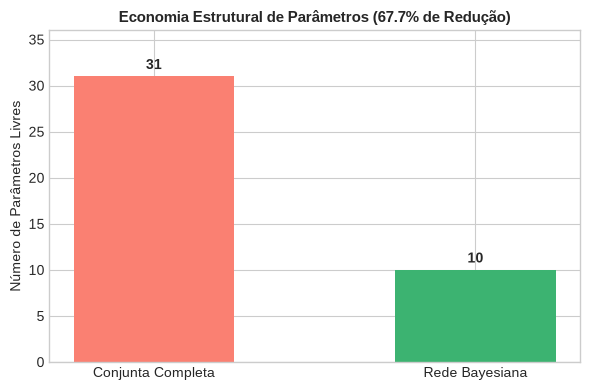

In [6]:
economy = bn_scratch.calculate_parameter_economy()

print("=== ECONOMIA FORMAL DE PARÂMETROS ===")
print(f"Variáveis no Domínio                  : {economy['num_variables']}")
print(f"Parâmetros na Conjunta Completa (2^5 - 1): {economy['full_joint_parameters']}")
print(f"Parâmetros na Rede Bayesiana          : {economy['bayesian_network_parameters']}")
print(f"Parâmetros Economizados               : {economy['parameters_saved']} números")
print(f"Redução Percentual de Complexidade    : {economy['reduction_percentage']:.2f}%")

# Visualização da economia
plt.figure(figsize=(6, 4))
plt.bar(['Conjunta Completa', 'Rede Bayesiana'], [31, 10], color=['salmon', 'mediumseagreen'], width=0.5)
plt.ylabel('Número de Parâmetros Livres')
plt.title('Economia Estrutural de Parâmetros (67.7% de Redução)', fontsize=11, fontweight='bold')
for i, v in enumerate([31, 10]):
    plt.text(i, v + 0.8, f"{v}", ha='center', fontweight='bold')
plt.ylim(0, 36)
plt.tight_layout()
plt.show()

### 7. Síntese dos Resultados da Etapa 5

| Critério | Especificação | Obtido | Status |
|---|---|---|---|
| **DAG Causal** | 4–6 nós interpretáveis | 5 nós com justificativas epidemiológicas | Conforme |
| **Inferência por Enumeração** | Implementação do zero | Idêntico ao pgmpy ($|\Delta| < 10^{-12}$) | Conforme |
| **d-Separação** | Análise de estruturas causais | Cadeia e Colisor verificados formalmente | Conforme |
| **Efeito Colisor** | Observar colisor abre o caminho | Demonstrado ($S \to A \leftarrow N$) | Conforme |
| **Economia de Parâmetros** | Comparação com $2^n - 1$ | 10 vs. 31 parâmetros (67.7% economia) | Conforme |

As probabilidades posteriores geradas pela Rede Bayesiana (ex.: $P(A=1 \mid e)$) servirão diretamente como entrada antecedente para o **Sistema Fuzzy Mamdani na Etapa 6**.